In [4]:
import pandas as pd

In [40]:
pip install xgboost lightgbm shap

     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     --------------------------------- ------ 51.2/61.0 kB 1.3 MB/s eta 0:00:01
     -------------------------------------- 61.0/61.0 kB 804.9 kB/s eta 0:00:00
     ---------------------------------------- 0.0/57.4 kB ? eta -:--:--
     ----------------------------------- ---- 51.2/57.4 kB ? eta -:--:--
     ---------------------------------------- 57.4/57.4 kB 1.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.2/101.7 MB 5.3 MB/s eta 0:00:20
   ---------------------------------------- 0.5/101.7 MB 6.7 MB/s eta 0:00:16
   ---------------------------------------- 0.9/101.7 MB 6.6 MB/s eta 0:00:16
   ---------------------------------------- 1.1/101.7 MB 6.2 MB/s eta 0:00:17
   ---------------------------------------- 1.1/101.7 MB 6.2 MB/s eta 0:00:17
   ---------------------------------------- 1.1/101.7 MB 6.2 MB/s eta 0:00:17
   -

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
df= pd.read_csv(r"D:\projects\telco customer churn\dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [8]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [14]:
print(df.shape)


(7043, 21)


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [17]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [19]:
df['TotalCharges'].unique()

<StringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',
 ...
 '2625.25', '6886.25',  '1495.1',   '743.3',  '1419.4',  '1990.5',  '7362.9',
  '346.45',   '306.6',  '6844.5']
Length: 6531, dtype: str

# DATA PREPARATION

#Total Charges dtype->string -> convert to numeric

In [23]:
df['TotalCharges'].dtype

dtype('float64')

In [22]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [24]:
print(df[df["TotalCharges"].isna()][["tenure", "TotalCharges"]])  # confirm tenure is 0

      tenure  TotalCharges
488        0           NaN
753        0           NaN
936        0           NaN
1082       0           NaN
1340       0           NaN
3331       0           NaN
3826       0           NaN
4380       0           NaN
5218       0           NaN
6670       0           NaN
6754       0           NaN


In [25]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [28]:
df['TotalCharges'].isnull().sum()

np.int64(0)

#Drop customer id and encoding the target

In [30]:
df= df.drop(columns="customerID")

KeyError: "['customerID'] not found in axis"

In [32]:
df["Churn"] = (df["Churn"] == "Yes").astype(int)

In [ ]:
print(df.isna().sum().sum(), "missing values left")
print(df["Churn"].mean())  

0 missing values left
0.2653698707936959


# EDA

#

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64 

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn, dtype: float64 

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: Churn, dtype: float64 

TechSupport
No                     0.416
Yes                    0.152
No internet service    0.074
Name: Churn, dtype: float64 



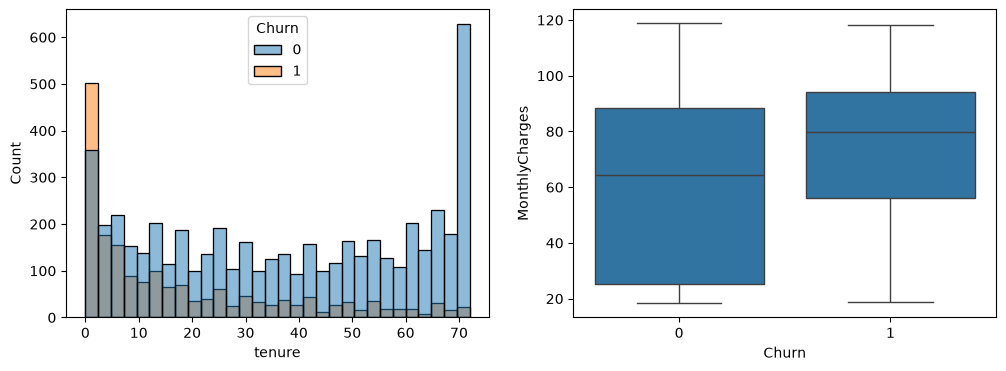

In [37]:
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    print(df.groupby(col)["Churn"].mean().sort_values(ascending=False).round(3), "\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[0])
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
plt.show()

# FEATURE ENGINEERING

In [41]:
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

df["num_services"] = (df[service_cols] == "Yes").sum(axis=1)
df["charges_per_month"] = df["TotalCharges"] / (df["tenure"] + 1)
df["tenure_bucket"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72],
                             labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)

# MODEL BUILDING

#data split

In [42]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# processing pipeline

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

C:\Users\ARCHANAA\AppData\Local\Temp\ipykernel_23368\337274347.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns.tolist()
C:\Users\ARCHANAA\AppData\Local\Temp\ipykernel_23368\337274347.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are excluded by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `exclude` to remove them, or to `include` to keep them and silence this warning.
See https://pandas.pydata.org/docs/dev/user

#Comparing models with cross validation

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "logreg": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "rf": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "xgb": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                         scale_pos_weight=pos_weight, eval_metric="logloss", random_state=42),
    "lgbm": LGBMClassifier(n_estimators=300, learning_rate=0.05,
                           class_weight="balanced", random_state=42, verbose=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    pipe = Pipeline([("pre", pre), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    print(f"{name:7s} PR-AUC: {scores.mean():.3f} (+/- {scores.std():.3f})")

logreg  PR-AUC: 0.668 (+/- 0.014)
rf      PR-AUC: 0.617 (+/- 0.029)
xgb     PR-AUC: 0.662 (+/- 0.018)
lgbm    PR-AUC: 0.648 (+/- 0.023)


#Choosing threshold by business cost

In [ ]:
offer_cost = 500        # cost of a retention offer per customer contacted
customer_value = 5000   # value of a retained customer
save_rate = 0.30        # share of true churners who accept the offer

thresholds = np.linspace(0.05, 0.95, 91)
profits = []
for t in thresholds:
    pred = proba >= t
    tp = ((pred == 1) & (y_test == 1)).sum()
    fp = ((pred == 1) & (y_test == 0)).sum()
    profits.append(tp * (customer_value * save_rate - offer_cost) - fp * offer_cost)

best_t = thresholds[int(np.argmax(profits))]
print("Best threshold:", round(best_t, 2), "| Profit:", max(profits))

plt.plot(thresholds, profits); plt.xlabel("Threshold"); plt.ylabel("Expected profit"); plt.show()

In [47]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             classification_report, confusion_matrix)

best = Pipeline([("pre", pre), ("model", models["xgb"])])
best.fit(X_train, y_train)

proba = best.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("PR-AUC :", round(average_precision_score(y_test, proba), 3))
print(classification_report(y_test, (proba >= 0.5).astype(int)))

ROC-AUC: 0.84
PR-AUC : 0.656
              precision    recall  f1-score   support

           0       0.91      0.75      0.82      1035
           1       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



#Explaining model using shap

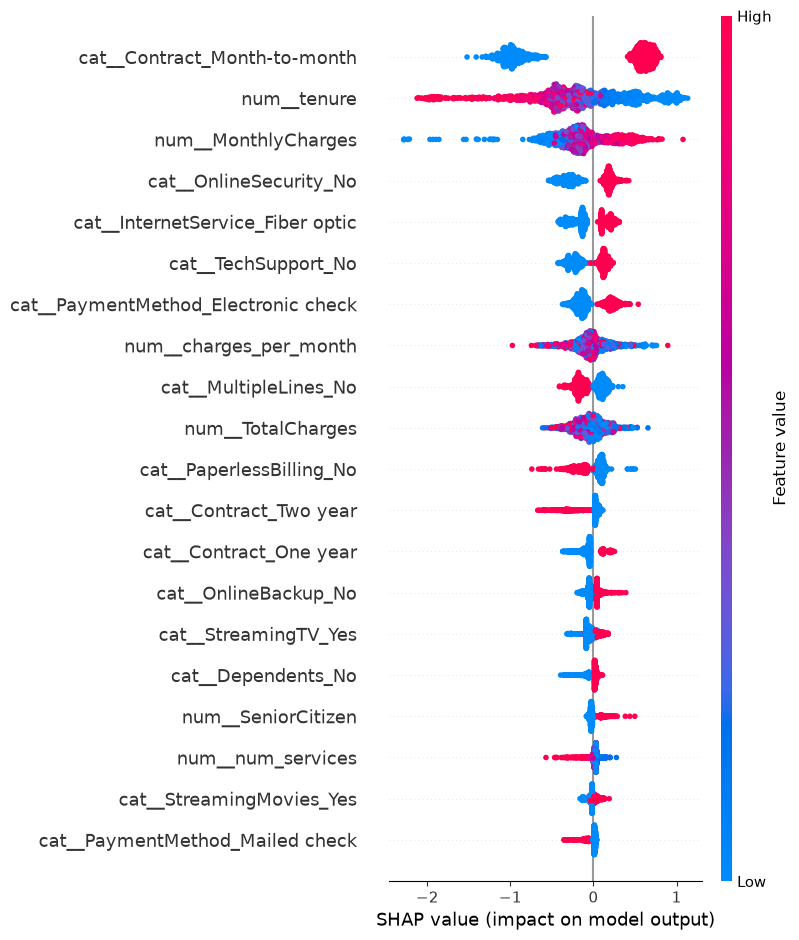

In [48]:
import shap

Xt = best.named_steps["pre"].transform(X_test)
names = best.named_steps["pre"].get_feature_names_out()

explainer = shap.TreeExplainer(best.named_steps["model"])
shap_values = explainer.shap_values(Xt)

shap.summary_plot(shap_values, Xt, feature_names=names)

#storing model in joblit for streamlit

In [49]:
import joblib
joblib.dump(best, "churn_pipeline.joblib")

['churn_pipeline.joblib']